In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

columns = ["Income", "DTI", "LoanAmount", "CreditScore", "EmploymentLength",
           "Purpose", "HomeOwnership", "State", "IssueYear"]
df = pd.read_csv("../data/processed/loans_clean.csv", usecols=columns)

X_pca = np.load("../data/processed/X_pca.npy")
X_scaled = np.load("../data/processed/X_scaled.npy")
sample_idx = np.load("../data/processed/sample_idx.npy")
labels = np.load("../data/processed/labels_kmeans.npy")

with open("../models/clustering_info.json") as file:
    K = json.load(file)["k"]
with open("../models/feature_info.json") as file:
    feature_names = json.load(file)["feature_names"]

assert len(labels) == len(df), "labels and data have different lengths"
print("K =", K, "| segment sizes:", np.bincount(labels))

K = 5 | segment sizes: [345055 286607 155730 293888 266401]


In [14]:
def quality(points, cluster_labels, sample_cap=5_000):
    """Standard quality numbers for one clustering. Noise points (label -1) are left out."""
    inside = cluster_labels != -1
    kept, kept_labels = points[inside], cluster_labels[inside]
    n_clusters = len(set(kept_labels))
    row = {
        "clusters": n_clusters,
        "noise_share": round(1 - inside.mean(), 3),
        "largest_share": round(pd.Series(kept_labels).value_counts(normalize=True).max(), 3),
    }
    if n_clusters >= 2:
        row["silhouette"] = round(silhouette_score(
            kept, kept_labels, sample_size=min(sample_cap, len(kept)), random_state=42), 3)
        row["davies_bouldin"] = round(davies_bouldin_score(kept, kept_labels), 3)
        row["calinski_harabasz"] = round(calinski_harabasz_score(kept, kept_labels), 1)
    return row


N_COMMON = 5_000
common_idx = sample_idx[:N_COMMON]
X_common = X_pca[common_idx]

kmeans_common = labels[common_idx]            # K-Means (fitted on all loans) on these 5,000 borrowers
hier_common = fcluster(linkage(pdist(X_common), method="ward"), t=K, criterion="maxclust")

X_db = X_pca[sample_idx]                      # DBSCAN works on the 20,000-borrower sample
k_dist = np.sort(NearestNeighbors(n_neighbors=10).fit(X_db).kneighbors(X_db)[0][:, -1])

rows = {
    f"K-Means (k={K})": quality(X_common, kmeans_common),
    f"Hierarchical, Ward (k={K})": quality(X_common, hier_common),
}
for name, share in {"DBSCAN, 80th percentile eps": 0.80, "DBSCAN, 95th percentile eps": 0.95}.items():
    rows[name] = quality(X_db, DBSCAN(eps=float(np.quantile(k_dist, share)), min_samples=10).fit_predict(X_db))

comparison = pd.DataFrame(rows).T
comparison["agreement_with_kmeans_ARI"] = np.nan
comparison.loc[f"Hierarchical, Ward (k={K})", "agreement_with_kmeans_ARI"] = round(
    adjusted_rand_score(kmeans_common, hier_common), 3)
comparison
comparison.round(3).to_csv("../models/algorithm_comparison.csv")

In [6]:
timing = []
for n in (1_000, 2_000, 4_000):
    points = X_pca[sample_idx[:n]]
    start = time.perf_counter()
    linkage(pdist(points), method="ward")
    hier_seconds = time.perf_counter() - start
    start = time.perf_counter()
    KMeans(n_clusters=K, n_init=3, random_state=42).fit(points)
    kmeans_seconds = time.perf_counter() - start
    timing.append({"borrowers": n, "hierarchical_seconds": round(hier_seconds, 2),
                   "kmeans_seconds": round(kmeans_seconds, 2)})
pd.DataFrame(timing)

,borrowers,hierarchical_seconds,kmeans_seconds
0,1000,0.02,0.07
1,2000,0.07,0.04
2,4000,0.29,0.02


In [7]:
df["Segment"] = labels

numeric = ["Income", "LoanAmount", "DTI", "CreditScore", "EmploymentLength"]
profile = df.groupby("Segment")[numeric].median().round(1)
profile.insert(0, "share", df["Segment"].value_counts(normalize=True).sort_index().round(3))
profile

,share,Income,LoanAmount,DTI,CreditScore,EmploymentLength
Segment,,,,,,
0,0.256,88000.0,17700.0,15.1,687.0,10.0
1,0.213,51000.0,12000.0,28.5,687.0,8.0
2,0.116,75000.0,14000.0,14.4,757.0,7.0
3,0.218,41000.0,5650.0,15.2,682.0,4.0
4,0.198,85000.0,17500.0,15.8,687.0,2.0


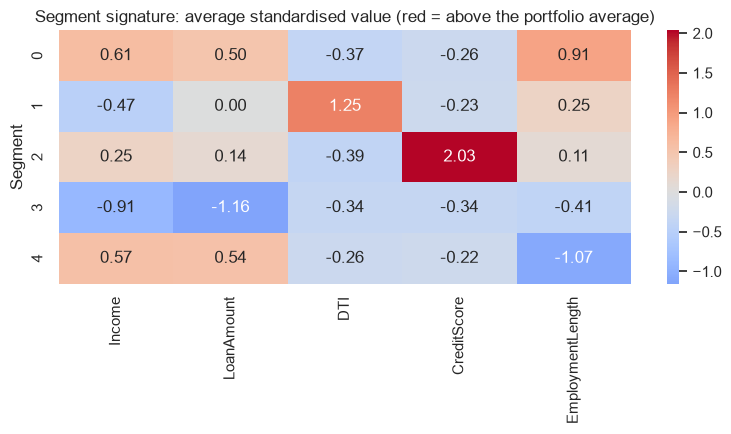

In [8]:
assert feature_names[:5] == ["Income", "LoanAmount", "DTI", "CreditScore", "EmploymentLength"]

signature = pd.DataFrame(X_scaled[:, :5], columns=feature_names[:5]).groupby(labels).mean()

plt.figure(figsize=(8, 4.5))
sns.heatmap(signature, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Segment signature: average standardised value (red = above the portfolio average)")
plt.ylabel("Segment")
plt.tight_layout()
plt.savefig("../docs/figures/18_segment_signature.png", dpi=150, bbox_inches="tight")
plt.show()

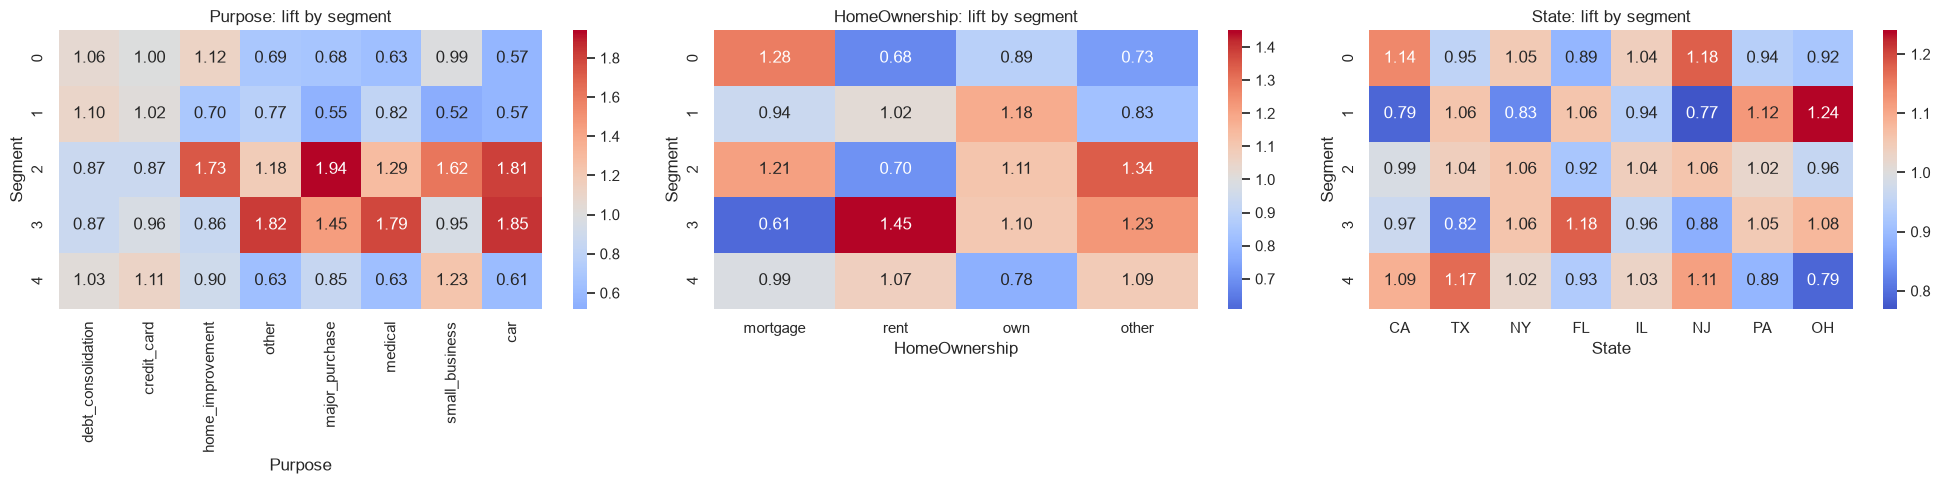

In [9]:
def lift_table(column, top=8):
    """How over- or under-represented each category is in each segment (1.00 = same as the portfolio)."""
    shares = pd.crosstab(df["Segment"], df[column], normalize="index")
    overall = df[column].value_counts(normalize=True)
    keep = overall.head(top).index
    return (shares[keep] / overall[keep]).round(2)


fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (column, top) in zip(axes, [("Purpose", 8), ("HomeOwnership", 4), ("State", 8)]):
    sns.heatmap(lift_table(column, top), annot=True, fmt=".2f", cmap="coolwarm", center=1, ax=ax)
    ax.set_title(f"{column}: lift by segment")
plt.tight_layout()
plt.savefig("../docs/figures/19_category_lift.png", dpi=150, bbox_inches="tight")
plt.show()

Share of each segment's loans issued in 2016 to 2018:
Segment
0    0.375
1    0.378
2    0.432
3    0.373
4    0.390
dtype: float64


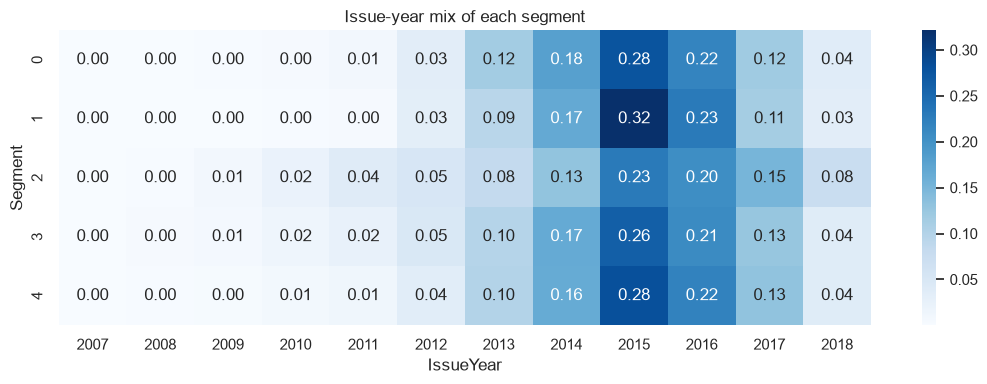

In [10]:
vintage = pd.crosstab(df["Segment"], df["IssueYear"], normalize="index")
recent_share = vintage[[2016, 2017, 2018]].sum(axis=1).round(3)
print("Share of each segment's loans issued in 2016 to 2018:")
print(recent_share)

plt.figure(figsize=(11, 4))
sns.heatmap(vintage, cmap="Blues", annot=True, fmt=".2f")
plt.title("Issue-year mix of each segment")
plt.tight_layout()
plt.savefig("../docs/figures/20_segment_vintage.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
# EDIT: write a short, neutral, descriptive name for every segment, using Cells 4 and 5
SEGMENT_NAMES = {
    0: "Established earners",
    1: "Stretched (high debt-to-income)",
    2: "Prime credit",
    3: "Smaller loans, lower income",
    4: "Higher income, short tenure",
}

assert set(SEGMENT_NAMES) == set(df["Segment"].unique()), "name every segment"

with open("../models/segment_names.json", "w") as file:
    json.dump({str(key): value for key, value in SEGMENT_NAMES.items()}, file, indent=2)
print(SEGMENT_NAMES)

{0: 'Established earners', 1: 'Stretched (high debt-to-income)', 2: 'Prime credit', 3: 'Smaller loans, lower income', 4: 'Higher income, short tenure'}
